In [49]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

In [6]:

df = pd.read_csv('sales_dataset.csv')

In [8]:
df.head(10)

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,discount_pct,shipping_fee,region,traffic_source,device,payment_method,order_status,returned
0,ORD-100001,2025-02-02,CUST-1070,USB-C Hub,Electronics,2.0,$35.86,5%,$8.99,East,Paid Search,Desktop,PayPal,Completed,No
1,ORD-100002,2025-02-04,CUST-1044,USB-C Hub,Electronics,3.0,$36.47,15%,$4.99,Central,Organic Search,Tablet,Apple Pay,Shipped,No
2,ORD-100003,2025-11-03,CUST-1140,Wireless Headphones,Electronics,1.0,$82.29,0%,$8.99,South,Paid Search,Tablet,Credit Card,Completed,No
3,ORD-100004,2025-10-28,CUST-1022,Skin Care Set,Beauty,2.0,$42.46,0%,$8.99,Central,Email,Desktop,Apple Pay,Completed,No
4,ORD-100005,2025-11-10,CUST-1023,Sunscreen SPF 50,Beauty,2.0,$15.53,0%,$6.99,North,Paid Search,Tablet,Apple Pay,Completed,No
5,ORD-100006,2025-12-21,CUST-1163,Desk Lamp,Home & Kitchen,2.0,$30.05,15%,$3.99,South,Social,Desktop,Credit Card,Completed,No
6,ORD-100007,2025-07-01,CUST-1128,Yoga Mat,Sports,1.0,$29.37,15%,$6.99,east,Direct,Mobile,Credit Card,Completed,No
7,ORD-100008,2025-12-20,CUST-1066,Water Bottle,Sports,4.0,$18.39,5%,$6.99,West,Organic Search,Tablet,Debit Card,Completed,No
8,ORD-100009,2025-06-18,CUST-1329,Sunscreen SPF 50,Beauty,2.0,$16.54,0%,$0.00,East,Direct,Desktop,Credit Card,Cancelled,No
9,ORD-100010,2025-06-09,CUST-1291,Wireless Headphones,Electronics,2.0,$76.99,15%,$6.99,East,Organic Search,Desktop,Credit Card,Shipped,No


In [66]:
''' Displays number of rows and columns are in the dataset. '''
df.shape

(1208, 15)

### "quantity, unit_price, discount_pct, and shipping_fee" these four coulumn shoud be float data type. Due to dollar sign and percentage sign it becomes string.

* Need processing data in this stage.

### Steps:
1. Remove dolar sign from beginning each data of "unit_price" and "shipping_fee" column.
2. Remove Percentage sign from "discount_pct" column.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1208 non-null   object 
 1   order_date      1208 non-null   object 
 2   customer_id     1194 non-null   object 
 3   product_name    1208 non-null   object 
 4   category        1208 non-null   object 
 5   quantity        1198 non-null   float64
 6   unit_price      1208 non-null   object 
 7   discount_pct    1208 non-null   object 
 8   shipping_fee    1196 non-null   object 
 9   region          1208 non-null   object 
 10  traffic_source  1208 non-null   object 
 11  device          1208 non-null   object 
 12  payment_method  1208 non-null   object 
 13  order_status    1208 non-null   object 
 14  returned        1208 non-null   object 
dtypes: float64(1), object(14)
memory usage: 141.7+ KB


### The customer_id, quantity, and shipping_fee columns has null values.

In [12]:
df.isnull().sum()

order_id           0
order_date         0
customer_id       14
product_name       0
category           0
quantity          10
unit_price         0
discount_pct       0
shipping_fee      12
region             0
traffic_source     0
device             0
payment_method     0
order_status       0
returned           0
dtype: int64

In [13]:
df.describe()

,quantity
count,1198.000000
mean,2.034224
std,1.082864
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,4.000000


In [ ]:
''' Copy the dataset to keep untouch the main dataset'''
df_copy = df.copy()
df_copy.head(10)

In [69]:
df_copy.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1203     True
1204     True
1205     True
1206     True
1207     True
Length: 1208, dtype: bool

In [73]:
''' Represent Duplicate values '''
df_copy[df_copy.duplicated()]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,discount_pct,shipping_fee,region,traffic_source,device,payment_method,order_status,returned
1200,ORD-100460,2025-12-06,CUST-1176,Sunscreen SPF 50,Beauty,4.0,$15.23,20%,$8.99,East,Email,Mobile,Apple Pay,Completed,No
1201,ORD-100458,2025-12-23,CUST-1330,Cotton T-Shirt,Fashion,1.0,$21.85,0%,$6.99,West,Direct,Tablet,PayPal,Shipped,No
1202,ORD-101023,2025-01-05,CUST-1128,Running Shoes,Fashion,2.0,$97.66,5%,$8.99,North,Paid Search,Desktop,Apple Pay,Completed,No
1203,ORD-100142,2025-01-18,CUST-1270,USB-C Hub,Electronics,4.0,$35.97,15%,$4.99,South,Social,Desktop,Credit Card,Completed,No
1204,ORD-100669,2025-08-28,CUST-1090,Sunscreen SPF 50,Beauty,1.0,$16.80,0%,$0.00,West,Email,Mobile,Apple Pay,Completed,No
1205,ORD-101012,2025-04-14,CUST-1236,Coffee Maker,Home & Kitchen,2.0,$53.97,15%,$3.99,North,Social,Mobile,Debit Card,Completed,No
1206,ORD-100152,2025-05-14,CUST-1158,Skin Care Set,Beauty,1.0,$37.95,0%,$0.00,North,Social,Mobile,Debit Card,Completed,No
1207,ORD-100831,2025-09-24,CUST-1277,Desk Lamp,Home & Kitchen,1.0,$33.89,5%,$6.99,East,Direct,Tablet,Credit Card,Completed,No


### The dataset has 8 duplicate values. It has been removed in this stage.

The (inplace = True) will make sure that the method does NOT return a new DataFrame, but it will remove all duplicates from the original DataFrame.

In [75]:
''' Remove all the duplicate values'''

df_copy.drop_duplicates(inplace = True)

In [76]:

''' Checking whether duplicate values remains or not.'''
df_copy[df_copy.duplicated()]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,discount_pct,shipping_fee,region,traffic_source,device,payment_method,order_status,returned


### Checking Null Values

* customer_id, quantity, and shipping_fee column contains with null values.

In [32]:
df_copy.isnull().sum()

order_id           0
order_date         0
customer_id       14
product_name       0
category           0
quantity          10
unit_price         0
discount_pct       0
shipping_fee      12
region             0
traffic_source     0
device             0
payment_method     0
order_status       0
returned           0
dtype: int64

* Here, Inconsistent data has been noticed. 
* Need to remane these as like the most common one. For example, east should be East.

In [42]:
df_copy['region'].value_counts()

region
Central    255
West       251
East       237
North      236
South      203
east         6
west         5
south        3
north        2
central      2
Name: count, dtype: int64

In [ ]:

''' Pull all the rows that contains with null value. '''
df_copy[df_copy.isnull().any(axis=1)]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,discount_pct,shipping_fee,region,traffic_source,device,payment_method,order_status,returned
28,ORD-100029,2025-03-10,CUST-1277,Skin Care Set,BEAUTY,1.0,$42.74,15%,NaN,Central,Direct,Mobile,PayPal,Completed,No
36,ORD-100037,2025-12-22,NaN,Yoga Mat,Sports,1.0,$27.28,0%,$4.99,West,Email,Tablet,Credit Card,Completed,No
121,ORD-100122,2025-02-21,CUST-1264,Cotton T-Shirt,Fashion,NaN,$21.98,5%,$8.99,Central,Social,Mobile,Debit Card,Completed,No
171,ORD-100172,2025-08-15,NaN,Skin Care Set,Beauty,1.0,$42.76,10%,$6.99,North,Paid Search,Tablet,Debit Card,Completed,No
189,ORD-100190,07/03/2025,CUST-1074,USB-C Hub,Electronics,NaN,$37.35,20%,$0.00,North,Paid Search,Desktop,Apple Pay,Completed,No
205,ORD-100206,2025-08-14,CUST-1056,Running Shoes,Fashion,2.0,$84.61,0%,NaN,North,Paid Search,Desktop,Debit Card,Completed,No
271,ORD-100272,2025-01-25,CUST-1226,Yoga Mat,Sports,1.0,$30.21,0%,NaN,West,Paid Search,Desktop,PayPal,Completed,No
297,ORD-100298,2025-03-10,CUST-1035,Desk Lamp,Home & Kitchen,4.0,$31.20,20%,NaN,Central,Social,Desktop,Apple Pay,Cancelled,No
305,ORD-100306,2025-05-28,CUST-1228,Desk Lamp,Home & Kitchen,1.0,$29.32,20%,NaN,North,Direct,Desktop,Debit Card,Completed,No
310,ORD-100311,2025-12-08,NaN,USB-C Hub,Electronics,2.0,$34.97,0%,$8.99,East,Referral,Mobile,Credit Card,Processing,No


In [48]:
df_copy[df_copy['customer_id'].isnull()]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,discount_pct,shipping_fee,region,traffic_source,device,payment_method,order_status,returned
36,ORD-100037,2025-12-22,NaN,Yoga Mat,Sports,1.0,$27.28,0%,$4.99,West,Email,Tablet,Credit Card,Completed,No
171,ORD-100172,2025-08-15,NaN,Skin Care Set,Beauty,1.0,$42.76,10%,$6.99,North,Paid Search,Tablet,Debit Card,Completed,No
310,ORD-100311,2025-12-08,NaN,USB-C Hub,Electronics,2.0,$34.97,0%,$8.99,East,Referral,Mobile,Credit Card,Processing,No
416,ORD-100417,2025-03-30,NaN,Sunscreen SPF 50,Beauty,4.0,$16.96,20%,$8.99,West,Paid Search,Tablet,Debit Card,Shipped,No
435,ORD-100436,2025-01-29,NaN,Wireless Headphones,Electronics,1.0,$81.83,10%,$3.99,North,Email,Mobile,Debit Card,Shipped,No
469,ORD-100470,2025-07-09,NaN,Desk Lamp,Home & Kitchen,3.0,$32.72,0%,$3.99,Central,Direct,Tablet,Credit Card,Shipped,No
494,ORD-100495,2025-04-23,NaN,Yoga Mat,Sports,4.0,$29.15,20%,$0.00,West,Referral,Mobile,Apple Pay,Shipped,No
750,ORD-100751,2025-09-22,NaN,Wireless Headphones,Electronics,1.0,$79.27,10%,$8.99,East,Organic Search,Desktop,Credit Card,Completed,No
925,ORD-100926,2025-11-10,NaN,Cotton T-Shirt,Fashion,1.0,$22.79,10%,$6.99,North,Referral,Mobile,PayPal,Cancelled,No
981,ORD-100982,2025-04-04,NaN,Coffee Maker,Home & Kitchen,4.0,$54.12,10%,$0.00,East,Social,Mobile,PayPal,Completed,No


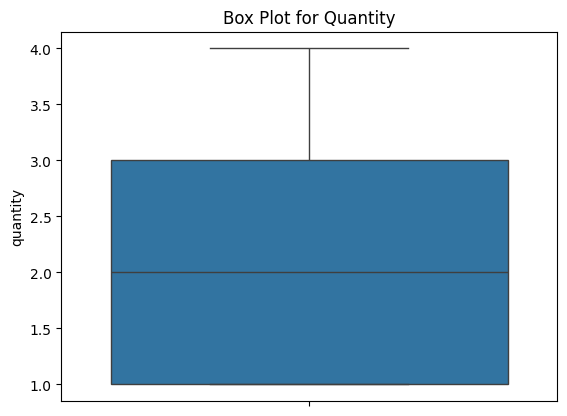

In [78]:
''' Checking Outliars'''
sns.boxplot(y=df_copy['quantity'])
plt.title("Box Plot for Quantity")
plt.show()

In [ ]:
''' Counting null vanues in each column'''
df_copy.isna().sum()

order_id           0
order_date         0
customer_id       14
product_name       0
category           0
quantity          10
unit_price         0
discount_pct       0
shipping_fee      12
region             0
traffic_source     0
device             0
payment_method     0
order_status       0
returned           0
dtype: int64

In [79]:
''' Create a dataframe with total number of null value in each column. '''
df_nullvalues = pd.DataFrame(df_copy.isna().sum())  
df_nullvalues.rename(columns={"Column_name": "Null_count"}, inplace=True)



<Axes: >

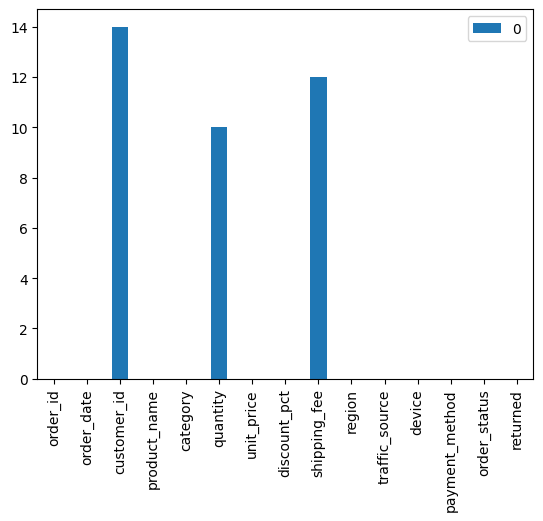

In [80]:
df_nullvalues.plot.bar()

In [81]:
''' Export the dataset'''
df.to_csv("df_copy.csv")